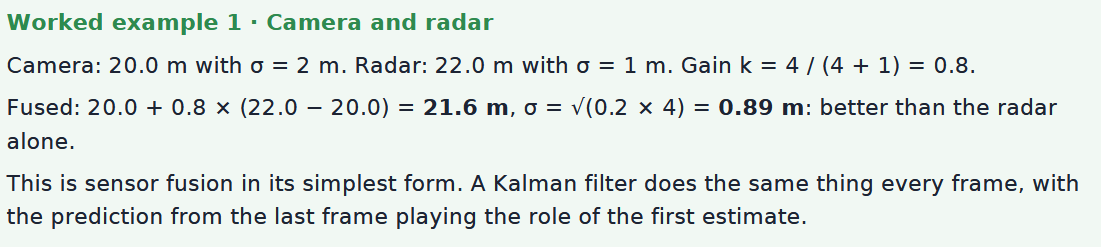

In [1]:
import numpy as np

def fuse(mu_a, var_a, mu_b, var_b):
    """Combine two independent Gaussian estimates of the same quantity."""
    k = var_a / (var_a + var_b)          # how much to trust b relative to a
    mu = mu_a + k * (mu_b - mu_a)
    var = (1 - k) * var_a                # = 1 / (1/var_a + 1/var_b)
    return mu, var, k

# camera says the car is 20.0 m away (sigma 2 m), radar says 22.0 m (sigma 1 m)
mu, var, k = fuse(20.0, 2.0**2, 22.0, 1.0**2)
print(f"fused: {mu:.2f} m, sigma {np.sqrt(var):.3f} m, weight on radar {k:.2f}")

fused: 21.60 m, sigma 0.894 m, weight on radar 0.80


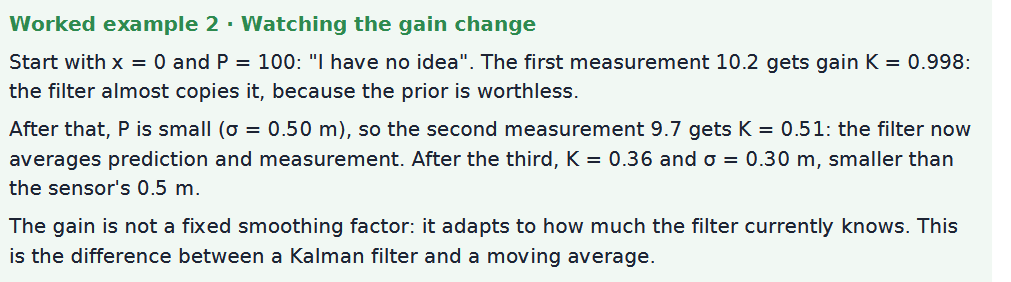

In [1]:
import numpy as np

def kf1d_step(x, P, z, q, r):
    """One cycle of a 1D Kalman filter with a constant-position model."""
    x_pred, P_pred = x, P + q            # predict: the state may have drifted by q
    K = P_pred / (P_pred + r)            # Kalman gain
    x_new = x_pred + K * (z - x_pred)    # update with the innovation z - x_pred
    P_new = (1 - K) * P_pred
    return x_new, P_new, K

x, P = 0.0, 100.0                        # start: no idea where it is (large P)
# measurements of a target at 10 m, sensor sigma 0.5 m
for z in [10.2, 9.7, 10.4]:
    x, P, K = kf1d_step(x, P, z, q=0.01, r=0.25)
    print(f"z = {z:5.1f}  ->  x = {x:6.3f}, sigma = {np.sqrt(P):.3f}, K = {K:.3f}")

z =  10.2  ->  x = 10.175, sigma = 0.499, K = 0.998
z =   9.7  ->  x =  9.933, sigma = 0.357, K = 0.509
z =  10.4  ->  x = 10.099, sigma = 0.298, K = 0.355
